# Gold Layer Preview: Storytelling & Governance Summaries (Workshop 3)
This notebook inspects the Gold Parquet outputs produced by PySpark (`datalake_gold/`), validates adherence to the shared long-format contract (`section, metric, dimension, period, value, unit, generated_utc`), and visualizes the core narrative: **which US volcanoes show unusual activity, and whether unrest is building or fading**.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

gold_dir = Path('../datalake_gold')
if not list(gold_dir.glob('storytelling_*.parquet')):
    gold_dir = Path('../workshop_3/samples')

story_files = sorted(gold_dir.glob('storytelling_*.parquet'))
gov_files = sorted(gold_dir.glob('governance_*.parquet'))

assert story_files, 'No storytelling_*.parquet found in datalake_gold/ or workshop_3/samples/'
story_df = pd.read_parquet(story_files[-1])
print('Loaded storytelling file:', story_files[-1].name, '-> shape:', story_df.shape)
display(story_df.dtypes)
display(story_df.groupby(['section', 'metric', 'unit'], dropna=False)['value'].agg(['count', 'mean', 'min', 'max']))

Loaded storytelling file: storytelling_20261120_040850.parquet -> shape: (6041, 7)


section                     str
metric                      str
dimension                   str
period                   object
value                   float64
unit                        str
generated_utc    datetime64[ns]
dtype: object

count  \
section              metric                         unit                 
alerts_breakdown     volcanoes_by_observatory_alert volcanoes        9   
                     volcanoes_by_region_color      volcanoes       15   
earthquakes_baseline baseline_p90                   earthquakes    115   
                     baseline_ratio                 ratio          115   
                     weekly_count                   earthquakes    115   
earthquakes_weekly   earthquakes                    records         27   
source_comparison    lexicon_mean                   score            2   
                     mean_text_length               characters       2   
                     records                        records          2   
                     vader_mean                     score            2   
tone_weekly          alert_level_mean               ordinal_1_4    882   
                     lexicon_mean                   score         3783   
                     vader_mean                     score          882   
top_keywords         frequency                      count           45   
                     mean_lexicon_tone              score           45   

                                                                        mean  \
section              metric                         unit                       
alerts_breakdown     volcanoes_by_observatory_alert volcanoes       6.000000   
                     volcanoes_by_region_color      volcanoes       3.600000   
earthquakes_baseline baseline_p90                   earthquakes     8.973913   
                     baseline_ratio                 ratio           0.778962   
                     weekly_count                   earthquakes     3.417391   
earthquakes_weekly   earthquakes                    records        21.925926   
source_comparison    lexicon_mean                   score           0.667509   
                     mean_text_length               characters   2054.114474   
                     records                        records      8273.000000   
                     vader_mean                     score           0.048768   
tone_weekly          alert_level_mean               ordinal_1_4     2.494602   
                     lexicon_mean                   score           0.616988   
                     vader_mean                     score          -0.012273   
top_keywords         frequency                      count        5027.066667   
                     mean_lexicon_tone              score           0.740412   

                                                                         min  \
section              metric                         unit                       
alerts_breakdown     volcanoes_by_observatory_alert volcanoes       1.000000   
                     volcanoes_by_region_color      volcanoes       1.000000   
earthquakes_baseline baseline_p90                   earthquakes     1.000000   
                     baseline_ratio                 ratio           0.012579   
                     weekly_count                   earthquakes     1.000000   
earthquakes_weekly   earthquakes                    records         1.000000   
source_comparison    lexicon_mean                   score           0.485122   
                     mean_text_length               characters   1434.777778   
                     records                        records         9.000000   
                     vader_mean                     score          -0.076633   
tone_weekly          alert_level_mean               ordinal_1_4     1.200000   
                     lexicon_mean                   score          -0.971500   
                     vader_mean                     score          -0.679087   
top_keywords         frequency                      count        1580.000000   
                     mean_lexicon_tone              score          -0.570165   

                                                                          max  
sect

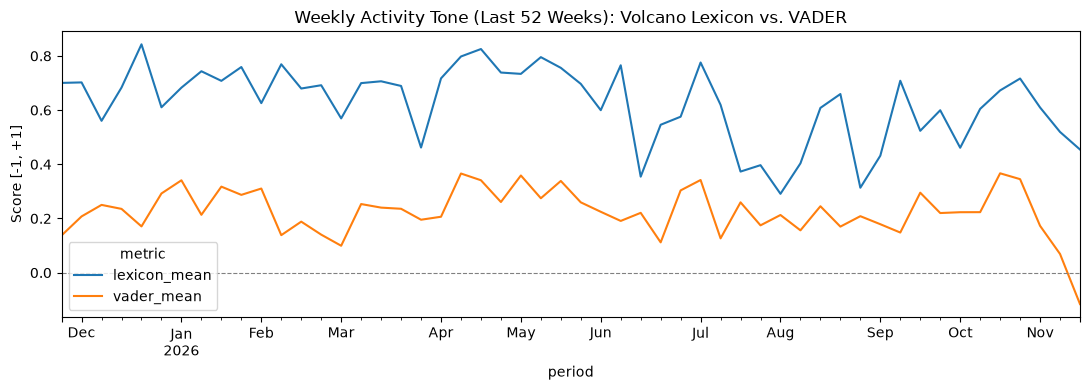

In [2]:
# 1. Weekly Activity Tone: Volcanic Domain Lexicon vs. VADER
tone = story_df[(story_df['section'] == 'tone_weekly') & (story_df['dimension'] == 'ALL')].copy()
if not tone.empty:
    tone['period'] = pd.to_datetime(tone['period'])
    piv = tone.pivot(index='period', columns='metric', values='value').sort_index()
    ax = piv[['lexicon_mean', 'vader_mean']].tail(52).plot(figsize=(11, 4), title='Weekly Activity Tone (Last 52 Weeks): Volcano Lexicon vs. VADER')
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    ax.set_ylabel('Score [-1, +1]')
    plt.tight_layout()
    plt.show()
else:
    print('No tone_weekly rows yet (run notices backfill + Silver first).')

metric,frequency,mean_lexicon_tone
dimension,,
unigram:lava,15315.0,0.942311
unigram:activity,14481.0,0.635501
unigram:volcano,14116.0,0.660997
unigram:summit,12136.0,0.867337
unigram:satellite,8223.0,0.675947
unigram:crater,8195.0,0.736170
unigram:mount,6464.0,-0.570165
unigram:lake,6405.0,0.575321
unigram:continues,6246.0,0.829058


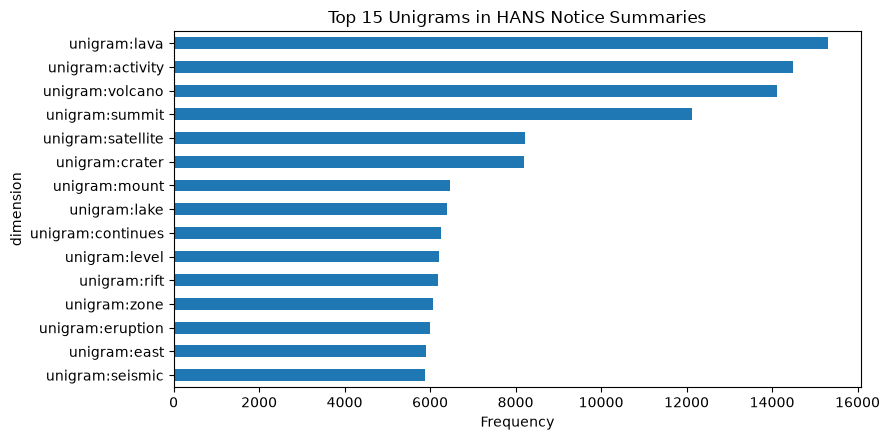

In [3]:
# 2. Top Keywords & Bigrams and Mean Activity Tone
kw = story_df[story_df['section'] == 'top_keywords'].copy()
if not kw.empty:
    kw_piv = kw.pivot(index='dimension', columns='metric', values='value').sort_values('frequency', ascending=False)
    display(kw_piv.head(20))
    top15 = kw_piv[kw_piv.index.str.startswith('unigram:')].head(15).sort_values('frequency')
    top15['frequency'].plot(kind='barh', figsize=(9, 4.5), title='Top 15 Unigrams in HANS Notice Summaries')
    plt.xlabel('Frequency')
    plt.tight_layout()
    plt.show()

In [4]:
# 3. API (HANS) vs. Scraping (USGS Volcano Updates) Comparison
src_cmp = story_df[story_df['section'] == 'source_comparison']
if not src_cmp.empty:
    display(src_cmp.pivot(index='dimension', columns='metric', values='value'))

# 4. US3: Weekly Earthquakes vs. Volcano Historical p90 Baseline
eq_base = story_df[story_df['section'] == 'earthquakes_baseline']
if not eq_base.empty:
    ratios = eq_base[eq_base['metric'] == 'baseline_ratio'].sort_values('value', ascending=False)
    print('Top volcano-weeks exceeding historical p90 seismic baseline:')
    display(ratios.head(15))

# 5. US1/US6: Current Alerts by Observatory & Region
alerts = story_df[story_df['section'] == 'alerts_breakdown']
if not alerts.empty:
    display(alerts[['metric', 'dimension', 'value']])

metric,lexicon_mean,mean_text_length,records,vader_mean
dimension,,,,
usgs_hans_notices_api,0.849895,2673.451170,16537.0,0.174168
usgs_volcano_updates_scraping,0.485122,1434.777778,9.0,-0.076633


Top volcano-weeks exceeding historical p90 seismic baseline:


,section,metric,dimension,period,value,unit,generated_utc
5902,earthquakes_baseline,baseline_ratio,332020,2026-11-16,1.0,ratio,2026-11-20 04:08:50.406540
5903,earthquakes_baseline,baseline_ratio,332020,2026-10-19,1.0,ratio,2026-11-20 04:08:50.406540
5904,earthquakes_baseline,baseline_ratio,332020,2026-11-09,1.0,ratio,2026-11-20 04:08:50.406540
5905,earthquakes_baseline,baseline_ratio,332020,2026-10-05,1.0,ratio,2026-11-20 04:08:50.406540
5906,earthquakes_baseline,baseline_ratio,323160,2026-11-16,1.0,ratio,2026-11-20 04:08:50.406540
5907,earthquakes_baseline,baseline_ratio,312090,2026-11-16,1.0,ratio,2026-11-20 04:08:50.406540
5908,earthquakes_baseline,baseline_ratio,312270,2026-11-16,1.0,ratio,2026-11-20 04:08:50.406540
5909,earthquakes_baseline,baseline_ratio,312100,2026-11-16,1.0,ratio,2026-11-20 04:08:50.406540
5912,earthquakes_baseline,baseline_ratio,323200,2026-11-09,1.0,ratio,2026-11-20 04:08:50.406540
5915,earthquakes_baseline,baseline_ratio,321070,2026-11-09,1.0,ratio,2026-11-20 04:08:50.406540


,metric,dimension,value
6017,volcanoes_by_observatory_alert,UNKNOWN|NORMAL,5.0
6018,volcanoes_by_observatory_alert,cvo|NORMAL,6.0
6019,volcanoes_by_observatory_alert,calvo|NORMAL,2.0
6020,volcanoes_by_observatory_alert,hvo|NORMAL,7.0
6021,volcanoes_by_observatory_alert,yvo|NORMAL,1.0
6022,volcanoes_by_observatory_alert,avo|WATCH,1.0
6023,volcanoes_by_observatory_alert,avo|NORMAL,30.0
6024,volcanoes_by_observatory_alert,hvo|ADVISORY,1.0
6025,volcanoes_by_observatory_alert,nmi|ADVISORY,1.0
6026,volcanoes_by_region_color,Washington|GREEN,3.0


In [5]:
# 6. Governance Summary Preview (if available)
if gov_files:
    gov_df = pd.read_parquet(gov_files[-1])
    print('Loaded governance file:', gov_files[-1].name, '-> shape:', gov_df.shape)
    display(gov_df.head(20))
else:
    print('No governance_*.parquet found yet.')

Loaded governance file: governance_20261120_040813.parquet -> shape: (7, 7)


,section,metric,dimension,period,value,unit,generated_utc
0,volume_total,records,volcanoes,None,165.0,records,2026-11-20 04:08:13.717246
1,volume_total,records,eruptions,None,1283.0,records,2026-11-20 04:08:13.717246
2,volume_total,records,earthquakes,None,592.0,records,2026-11-20 04:08:13.717246
3,volume_total,records,alert_notices,None,54.0,records,2026-11-20 04:08:13.717246
4,volume_total,records,volcano_updates,None,9.0,records,2026-11-20 04:08:13.717246
5,volume_total,records,notices,None,16537.0,records,2026-11-20 04:08:13.717246
6,volume_total,records,quarantine,None,182.0,records,2026-11-20 04:08:13.717246
